# Create a Direct Lake semantic model with code

Everything in this notebook replaces clicking in the web modeler:
generate the model, add relationships, a date table, a measure table,
measures and a DAX UDF. One notebook, rerunnable on any lakehouse.

Prerequisites: run the lakehouse prep notebook first (DimDate), and attach the environment with semantic-link-labs.

In [1]:
# Setup: sempy reads and analyzes models, sempy_labs creates and changes them.
# sempy_labs comes from the attached environment, so no %pip install needed.

import sempy.fabric as fabric
import sempy_labs as labs
from sempy_labs.tom import connect_semantic_model
from sempy.relationships import plot_relationship_metadata
from importlib.metadata import version

print(f"semantic-link-labs {version('semantic-link-labs')}")

WORKSPACE = "Dataminds DEV"
DATASET = "SM_Contoso_DirectLake"
LAKEHOUSE = "LH_Contoso"

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 9, Finished, Available, Finished, False)

semantic-link-labs 0.17.1


## Generate the model

One function call. Schema-enabled lakehouse, so table names need the dbo. prefix.

In [2]:
labs.directlake.generate_direct_lake_semantic_model(
    dataset=DATASET,
    tables=[
        "dbo.DimCustomer",
        "dbo.DimProduct",
        "dbo.DimProductCategory",
        "dbo.DimProductSubcategory",
        "dbo.DimStore",
        "dbo.FactOnlineSales",
        "dbo.DimDate",
    ],
    source=LAKEHOUSE,
    source_workspace=WORKSPACE,
    workspace=WORKSPACE,
    overwrite=True,
)

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 10, Finished, Available, Finished, False)

🟢 The 'SM_Contoso_DirectLake' semantic model was created within the 'Dataminds DEV' workspace.
⌛ Refresh of the 'SM_Contoso_DirectLake' semantic model within the 'Dataminds DEV' workspace is in progress...
🟢 Refresh 'full' of the 'SM_Contoso_DirectLake' semantic model within the 'Dataminds DEV' workspace is complete.


## Relationships

These don't come over from the source. Six relationships in one loop.
DimDate gets marked as the official date table.

In [3]:
# Relationships don't come over from the lakehouse, so we add them via TOM.
# Existing ones are skipped, so the cell can safely run twice.
# Marking DimDate as date table makes time intelligence work.

rels = [
    ("FactOnlineSales", "ProductKey", "DimProduct", "ProductKey"),
    ("FactOnlineSales", "CustomerKey", "DimCustomer", "CustomerKey"),
    ("FactOnlineSales", "StoreKey", "DimStore", "StoreKey"),
    ("FactOnlineSales", "DateKey", "DimDate", "DateKey"),
    ("DimProduct", "ProductSubcategoryKey", "DimProductSubcategory", "ProductSubcategoryKey"),
    ("DimProductSubcategory", "ProductCategoryKey", "DimProductCategory", "ProductCategoryKey"),
]

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    existing = {
        (r.FromTable.Name, r.FromColumn.Name, r.ToTable.Name, r.ToColumn.Name)
        for r in tom.model.Relationships
    }
    for from_table, from_col, to_table, to_col in rels:
        if (from_table, from_col, to_table, to_col) in existing:
            print(f"Already exists: {from_table}[{from_col}] → {to_table}[{to_col}]")
            continue
        tom.add_relationship(
            from_table=from_table,
            from_column=from_col,
            to_table=to_table,
            to_column=to_col,
            from_cardinality="Many",
            to_cardinality="One",
            cross_filtering_behavior="OneDirection",
        )
    tom.mark_as_date_table(table_name="DimDate", column_name="DateKey")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 11, Finished, Available, Finished, False)

🟢 The 'DimDate' table has been marked as a date table using the 'DateKey' column as its primary date key.


## Refresh

New relationships need a recalculation before you can query them.
Direct Lake refresh = framing only (metadata), so this takes seconds.
Side effect: all resident columns are evicted, the model goes cold.

In [4]:
labs.refresh_semantic_model(dataset=DATASET, workspace=WORKSPACE, refresh_type="full")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 12, Finished, Available, Finished, False)

⌛ Refresh of the 'SM_Contoso_DirectLake' semantic model within the 'Dataminds DEV' workspace is in progress...
🟢 Refresh 'full' of the 'SM_Contoso_DirectLake' semantic model within the 'Dataminds DEV' workspace is complete.


## Verify

Sempy caches model metadata. Without refresh_tom_cache the relationship list
shows up empty and you think something is broken. It isn't.

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 13, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, c39d4830-3182-43c8-9477-c2a97c2fa87f)

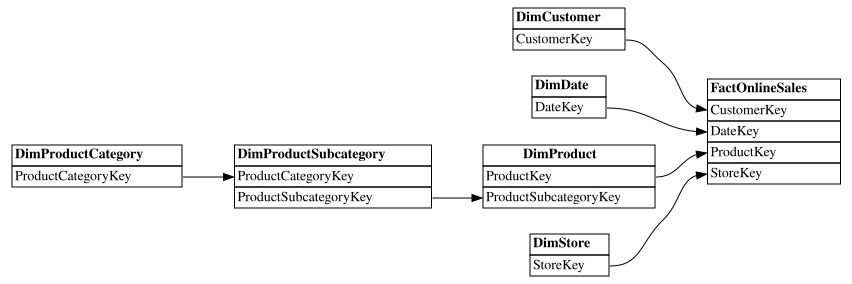

In [5]:
fabric.refresh_tom_cache(workspace=WORKSPACE)
rels_df = fabric.list_relationships(DATASET, workspace=WORKSPACE)
display(rels_df)
plot_relationship_metadata(rels_df)

## Measure table + measures

A dedicated measure table, the BPA-friendly way: calculated table with a
dummy expression, dummy column hidden. Format strings and descriptions
included from the start, so BPA has nothing to complain about later.

In [6]:
with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    tom.add_calculated_table(name="_Measures", expression='ROW("Dummy", BLANK())')

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 14, Finished, Available, Finished, False)

In [7]:
measures = [
    ("Total Sales", "SUMX(FactOnlineSales, FactOnlineSales[SalesQuantity] * FactOnlineSales[UnitPrice])", "#,0.00", "Revenue: quantity times unit price"),
    ("Total Cost",  "SUMX(FactOnlineSales, FactOnlineSales[SalesQuantity] * FactOnlineSales[UnitCost])",  "#,0.00", "Total cost of goods sold"),
    ("Margin %",    "DIVIDE([Total Sales] - [Total Cost], [Total Sales])",                                "0.0%",   "Gross margin as a percentage of sales"),
]

with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    tom.model.Tables["_Measures"].Columns["Dummy"].IsHidden = True
    for name, expr, fmt, desc in measures:
        tom.add_measure(table_name="_Measures", measure_name=name, expression=expr,
                        format_string=fmt, description=desc)

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 15, Finished, Available, Finished, False)

In [8]:
fabric.evaluate_dax(DATASET, workspace=WORKSPACE, dax_string="""
EVALUATE
SUMMARIZECOLUMNS(
    DimDate[Year],
    "Total Sales", [Total Sales],
    "Total Cost", [Total Cost],
    "Margin %", [Margin %]
)
""")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 16, Finished, Available, Finished, False)

,DimDate[Year],[Total Sales],[Total Cost],[Margin %]
0,2008,934403814.178,402964410.16,0.568747
1,2009,940877836.936,404708395.15,0.569861
2,2007,1108917269.99,469042146.17,0.577027


## DAX user-defined function

New in the platform, and it works through code already: set_user_defined_function.
UDFs need compatibility level 1702 or higher. One reusable function, one measure
that calls it. The comparison query proves it returns exactly the same numbers.

In [9]:
with connect_semantic_model(dataset=DATASET, workspace=WORKSPACE, readonly=False) as tom:
    print("Compatibility level:", tom.model.Database.CompatibilityLevel)

    tom.set_user_defined_function(
        name="SafeMargin",
        expression="(sales: SCALAR, cost: SCALAR) => DIVIDE(sales - cost, sales)",
    )
    tom.add_measure(
        table_name="_Measures",
        measure_name="Margin % (UDF)",
        expression="SafeMargin([Total Sales], [Total Cost])",
        format_string="0.0%",
        description="Margin via user-defined function",
    )

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 17, Finished, Available, Finished, False)

Compatibility level: 1702


In [10]:
fabric.evaluate_dax(DATASET, workspace=WORKSPACE, dax_string="""
EVALUATE
SUMMARIZECOLUMNS(
    DimDate[Year],
    "Margin classic", [Margin %],
    "Margin via UDF", [Margin % (UDF)]
)
""")

StatementMeta(, 626535a0-e4d5-4ec1-889f-1b89ae4e045a, 18, Finished, Available, Finished, False)

,DimDate[Year],[Margin classic],[Margin via UDF]
0,2008,0.568747,0.568747
1,2009,0.569861,0.569861
2,2007,0.577027,0.577027
